# Modèle SV-GARCH (notation `particles`)

$$
\begin{aligned}
y_t &= \sqrt{v_t}\,\epsilon_t \\
v_{t+1} &= \gamma + \alpha\,v_t + \beta\,v_t\,\zeta_t^2, \qquad v_0 = \tfrac{\gamma}{1-\alpha-\beta}
\end{aligned}
\qquad
\zeta_t = \varphi\,\epsilon_t + \sqrt{1-\varphi^2}\,\xi_t,
\quad \epsilon_t,\xi_t \overset{\text{i.i.d.}}{\sim} \mathcal{N}(0,1)
$$

avec $\gamma>0,\ \alpha,\beta\ge0,\ \alpha+\beta<1,\ 0\le\varphi\le1$. État latent : la variance $v_t$.

Densité d'observation (simple, car $y_t$ ne dépend que de $v_t$) :

$$
p(y_t \mid v_t) = \mathcal{N}\!\big(0,\ v_t\big).
$$

La complexité est dans la **transition** : $v_{t+1}$ dépend de $y_t$ via $\epsilon_t = y_t/\sqrt{v_t}$, d'où
$$
v_{t+1} = \gamma + \alpha v_t + \beta v_t\Big(\varphi\,\tfrac{y_t}{\sqrt{v_t}} + \sqrt{1-\varphi^2}\,\xi_t\Big)^2.
$$

In [4]:
import warnings; warnings.simplefilter('ignore')  # hide warnings

# standard libraries
from matplotlib import pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def simulate_svgarch(T, gamma, alpha, beta, phi, burn=1000, seed=None):
    """Simule (v, y) de longueur T pour le SV-GARCH."""
    rng = np.random.default_rng(seed)
    n = T + burn
    eps, xi = rng.standard_normal(n), rng.standard_normal(n)
    v, y = np.empty(n), np.empty(n)
    v[0] = gamma / (1.0 - alpha - beta)                 # moyenne inconditionnelle
    for t in range(n):
        y[t] = np.sqrt(v[t]) * eps[t]                   # observation
        if t < n - 1:
            zeta = phi * eps[t] + np.sqrt(1.0 - phi**2) * xi[t]
            v[t + 1] = gamma + alpha * v[t] + beta * v[t] * zeta**2   # propagation
    return v[burn:], y[burn:]                           # on jette le burn-in

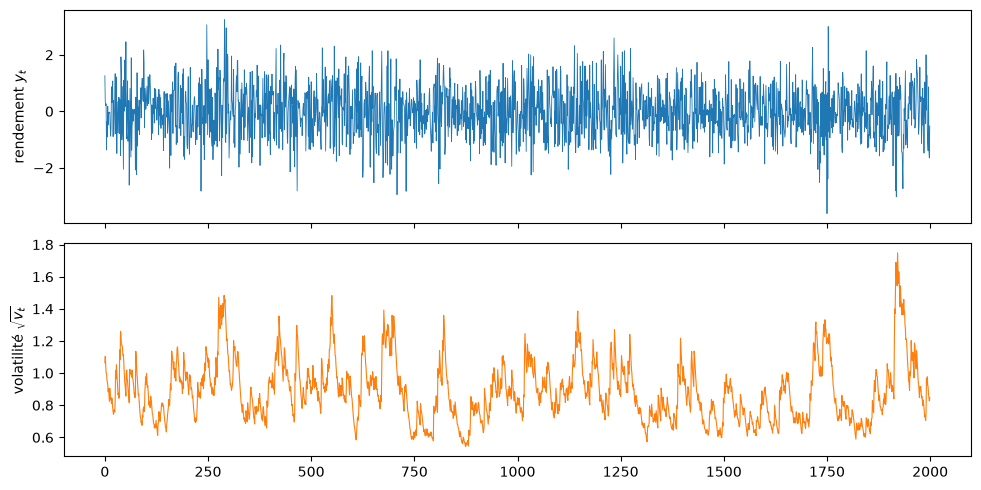

var(y) = 0.814   moyenne inconditionnelle de v = 1.000


In [5]:
v, y = simulate_svgarch(T=2000, gamma=0.02, alpha=0.88, beta=0.10, phi=0.5, seed=0)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(y, lw=0.6);              ax[0].set_ylabel("rendement $y_t$")
ax[1].plot(np.sqrt(v), lw=0.8, color="C1"); ax[1].set_ylabel("volatilité $\\sqrt{v_t}$")
plt.tight_layout(); plt.show()

print("var(y) = %.3f   moyenne inconditionnelle de v = %.3f" % (y.var(), 0.02/(1-0.88-0.10)))